In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn openpyxl


Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# understand the dataset

In [ ]:
df = pd.read_excel("HousePrice.xlsx") 

df.head()

,Area_sqft,Bedrooms,Bathrooms,Age_years,Distance_City_km,Parking,Location_Score,Crime_Rate,Income_Level_Lakh,Property_Type,House_Price_INR
0,3674,5,5,7,1.5,2,8.4,3.03,93.0,Villa,77423000
1,1360,1,1,10,9.5,0,8.2,3.98,94.8,Apartment,32387000
2,1794,3,2,19,23.4,1,4.1,5.03,73.2,Villa,31490000
3,1630,2,2,27,16.0,1,6.3,3.55,84.4,Townhouse,34006000
4,1595,4,4,0,11.1,3,6.6,3.69,79.3,Villa,38552000


In [10]:
df.shape

(800, 11)

In [11]:

df.columns

Index(['Area_sqft', 'Bedrooms', 'Bathrooms', 'Age_years', 'Distance_City_km',
       'Parking', 'Location_Score', 'Crime_Rate', 'Income_Level_Lakh',
       'Property_Type', 'House_Price_INR'],
      dtype='object')

In [12]:
df.describe()

,Area_sqft,Bedrooms,Bathrooms,Age_years,Distance_City_km,Parking,Location_Score,Crime_Rate,Income_Level_Lakh,House_Price_INR
count,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,8.000000e+02
mean,2316.145000,3.598750,2.977500,14.791250,15.663500,1.545000,6.064750,4.432338,77.252500,4.597371e+07
std,1009.866124,1.695241,1.524762,8.873618,8.388913,1.125637,2.215252,1.152775,18.850974,1.964986e+07
min,501.000000,1.000000,1.000000,0.000000,1.000000,0.000000,1.400000,1.450000,25.000000,4.408000e+06
25%,1474.250000,2.000000,1.000000,7.000000,8.300000,1.000000,4.300000,3.437500,63.175000,2.892575e+07
50%,2268.000000,4.000000,3.000000,15.000000,16.000000,2.000000,5.950000,4.440000,77.600000,4.517350e+07
75%,3239.500000,5.000000,4.000000,22.000000,22.725000,3.000000,7.900000,5.382500,91.325000,6.352100e+07
max,3999.000000,6.000000,5.000000,30.000000,30.000000,3.000000,10.000000,7.150000,126.800000,8.436900e+07


In [13]:
df.tail(10)

,Area_sqft,Bedrooms,Bathrooms,Age_years,Distance_City_km,Parking,Location_Score,Crime_Rate,Income_Level_Lakh,Property_Type,House_Price_INR
790,955,1,1,20,6.7,3,8.5,3.22,114.1,Townhouse,24020000
791,1328,3,2,9,22.4,1,4.5,5.01,71.0,Apartment,26199000
792,1394,4,3,26,9.3,1,6.4,4.40,80.6,Villa,30115000
793,1884,4,3,14,24.3,2,3.3,5.19,58.5,Apartment,35853000
794,2458,2,1,29,29.9,3,2.5,5.72,28.7,Apartment,37434000
795,3572,6,5,8,1.9,1,9.9,3.07,111.8,Townhouse,77053000
796,2934,5,4,1,27.0,3,1.7,5.48,48.2,Apartment,52857000
797,2496,4,3,4,19.1,0,5.1,4.41,75.0,Villa,50645000
798,2895,5,5,5,29.2,0,2.8,5.43,47.5,Apartment,55395000
799,689,1,1,6,14.5,1,7.0,4.07,80.2,Apartment,17107000


In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df["Property_Type"].unique()

array(['Villa', 'Apartment', 'Townhouse'], dtype=object)

#  Exploratory Data Analysis

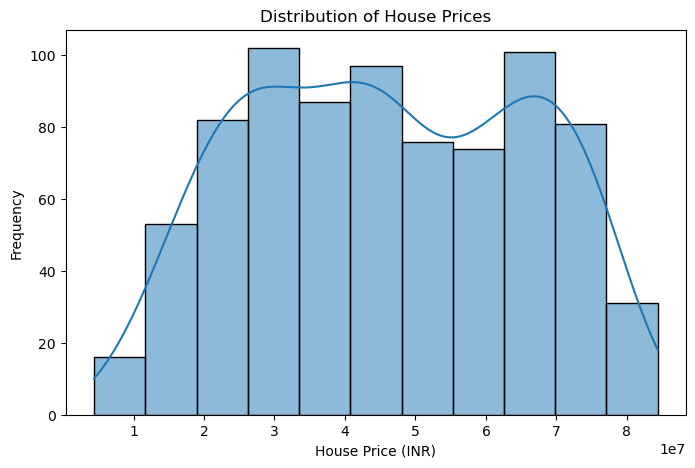

In [16]:
plt.figure(figsize=(8,5))
sns.histplot(df["House_Price_INR"], kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("House Price (INR)")
plt.ylabel("Frequency")
plt.show()

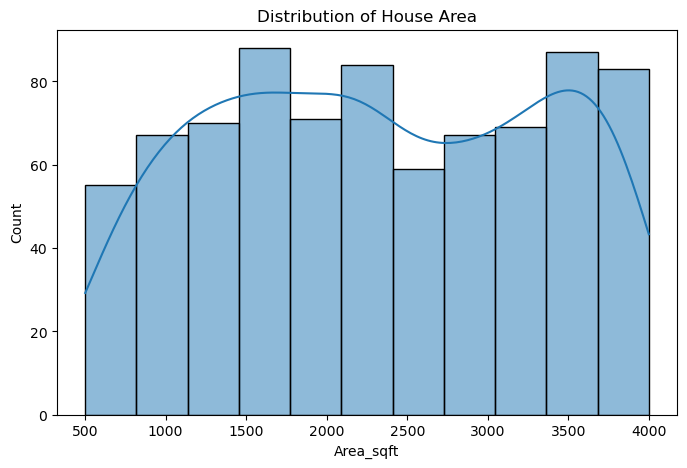

In [17]:
plt.figure(figsize=(8,5))
sns.histplot(df["Area_sqft"], kde=True)
plt.title("Distribution of House Area")
plt.show()

# categorical analysis

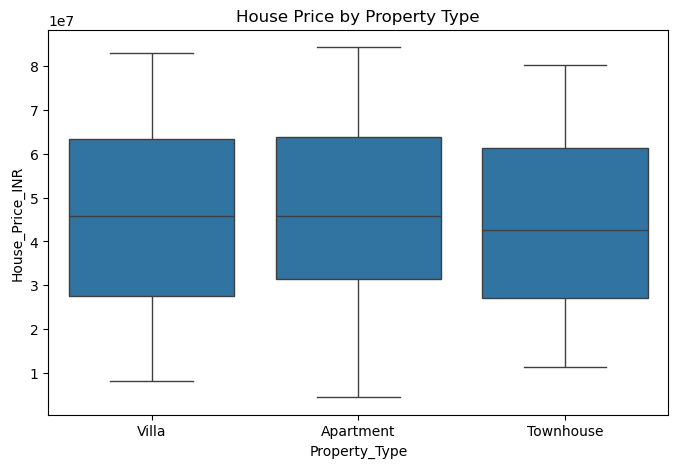

In [18]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="Property_Type", y="House_Price_INR")
plt.title("House Price by Property Type")
plt.show()

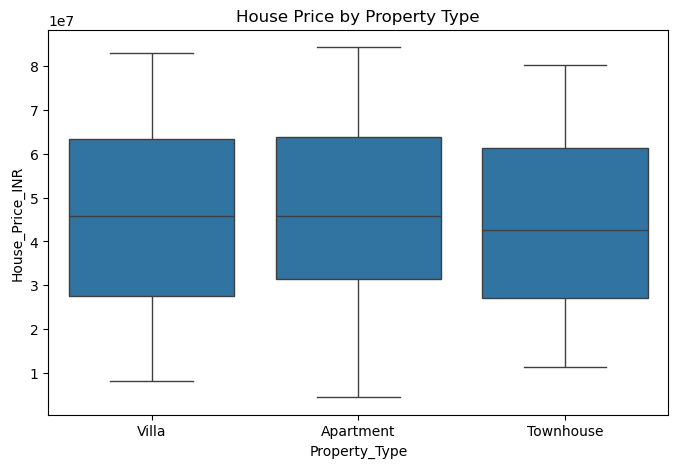

In [19]:
# compare prices
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="Property_Type", y="House_Price_INR")
plt.title("House Price by Property Type")
plt.show()

# Relationship Between Features and Price

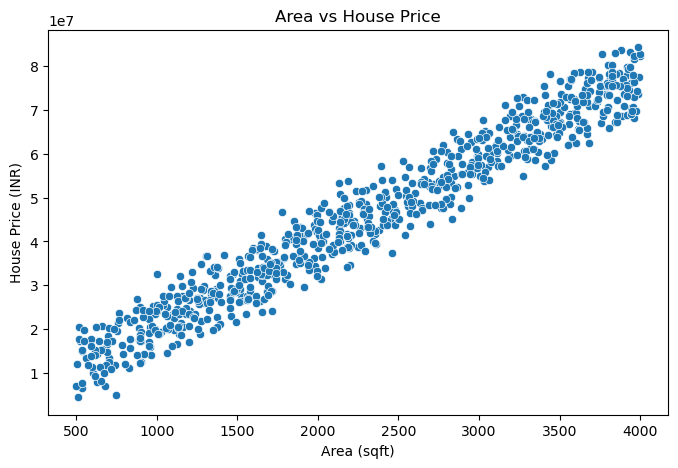

In [20]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="Area_sqft",
    y="House_Price_INR"
)

plt.title("Area vs House Price")
plt.xlabel("Area (sqft)")
plt.ylabel("House Price (INR)")
plt.show()

# Bedrooms vs Price

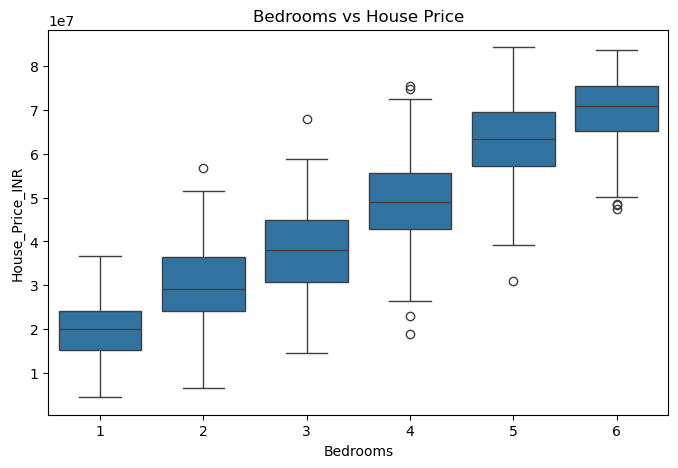

In [21]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Bedrooms",
    y="House_Price_INR"
)

plt.title("Bedrooms vs House Price")
plt.show()


# Age vs Price

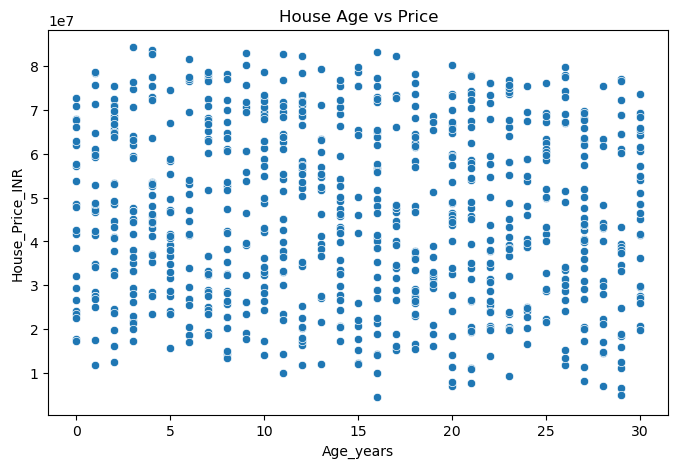

In [22]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="Age_years",
    y="House_Price_INR"
)

plt.title("House Age vs Price")
plt.show()

# Correlation Analysis

In [23]:
numeric_df = df.select_dtypes(include=np.number)

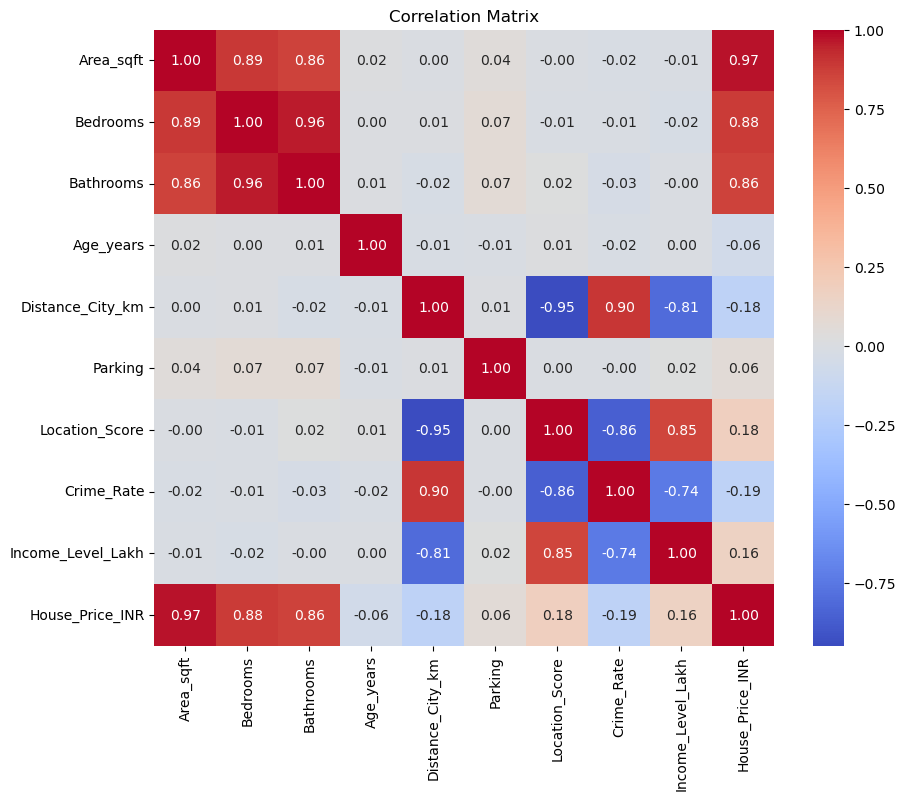

In [24]:
corr = numeric_df.corr()

plt.figure(figsize=(10,8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

# Prepare X and y

In [29]:
X = df.drop("House_Price_INR", axis=1)
y = df["House_Price_INR"]

In [31]:
X

,Area_sqft,Bedrooms,Bathrooms,Age_years,Distance_City_km,Parking,Location_Score,Crime_Rate,Income_Level_Lakh,Property_Type
0,3674,5,5,7,1.5,2,8.4,3.03,93.0,Villa
1,1360,1,1,10,9.5,0,8.2,3.98,94.8,Apartment
2,1794,3,2,19,23.4,1,4.1,5.03,73.2,Villa
3,1630,2,2,27,16.0,1,6.3,3.55,84.4,Townhouse
4,1595,4,4,0,11.1,3,6.6,3.69,79.3,Villa
...,...,...,...,...,...,...,...,...,...,...
795,3572,6,5,8,1.9,1,9.9,3.07,111.8,Townhouse
796,2934,5,4,1,27.0,3,1.7,5.48,48.2,Apartment
797,2496,4,3,4,19.1,0,5.1,4.41,75.0,Villa
798,2895,5,5,5,29.2,0,2.8,5.43,47.5,Apartment


In [33]:
y

0      77423000
1      32387000
2      31490000
3      34006000
4      38552000
         ...   
795    77053000
796    52857000
797    50645000
798    55395000
799    17107000
Name: House_Price_INR, Length: 800, dtype: int64

# Handle Categorical Variable

In [34]:
categorical_features = ["Property_Type"]

numeric_features = [
    "Area_sqft",
    "Bedrooms",
    "Bathrooms",
    "Age_years",
    "Distance_City_km",
    "Parking",
    "Location_Score",
    "Crime_Rate",
    "Income_Level_Lakh"
]

In [35]:
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Train/Test Split

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [38]:
X_train.shape

(640, 10)

In [41]:
X_test.shape

(160, 10)


# Linear Regression

In [42]:
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

In [43]:
linear_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Area_sqft', 'Bedrooms',
                                                   'Bathrooms', 'Age_years',
                                                   'Distance_City_km',
                                                   'Parking', 'Location_Score',
                                                   'Crime_Rate',
                                                   'Income_Level_Lakh']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Property_Type'])])),
                ('model', LinearRegression())])

In [44]:
y_pred_linear = linear_model.predict(X_test)

# Evaluate Linear Regression

In [46]:
mae_linear = mean_absolute_error(y_test, y_pred_linear)

print("MAE:", mae_linear)

MAE: 1234310.1069232333


In [47]:
rmse_linear = np.sqrt(
    mean_squared_error(y_test, y_pred_linear)
)

print("RMSE:", rmse_linear)

RMSE: 1553445.4558581188


In [48]:
r2_linear = r2_score(y_test, y_pred_linear)

print("R2 Score:", r2_linear)

R2 Score: 0.9938643075772029


# Actual vs Predicted Visualization

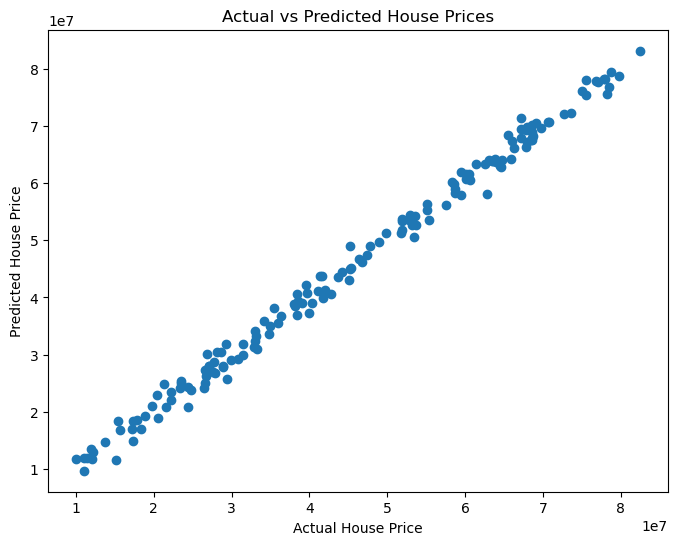

In [49]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred_linear)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

# Ridge Regression

In [51]:
ridge_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", Ridge(alpha=1.0))
    ]
)

In [52]:
ridge_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Area_sqft', 'Bedrooms',
                                                   'Bathrooms', 'Age_years',
                                                   'Distance_City_km',
                                                   'Parking', 'Location_Score',
                                                   'Crime_Rate',
                                                   'Income_Level_Lakh']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Property_Type'])])),
                ('model', Ridge())])

In [53]:
y_pred_ridge = ridge_model.predict(X_test)

In [54]:
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)

rmse_ridge = np.sqrt(
    mean_squared_error(y_test, y_pred_ridge)
)

r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge MAE:", mae_ridge)
print("Ridge RMSE:", rmse_ridge)
print("Ridge R2:", r2_ridge)

Ridge MAE: 1232810.066580826
Ridge RMSE: 1549199.2991281766
Ridge R2: 0.9938978040930267


# Lasso Regression

In [55]:
lasso_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", Lasso(alpha=0.1, max_iter=10000))
    ]
)

In [56]:
lasso_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Area_sqft', 'Bedrooms',
                                                   'Bathrooms', 'Age_years',
                                                   'Distance_City_km',
                                                   'Parking', 'Location_Score',
                                                   'Crime_Rate',
                                                   'Income_Level_Lakh']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Property_Type'])])),
                ('model', Lasso(alpha=0.1, max_iter=10000))])

In [57]:
y_pred_lasso = lasso_model.predict(X_test)

In [58]:
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)

rmse_lasso = np.sqrt(
    mean_squared_error(y_test, y_pred_lasso)
)

r2_lasso = r2_score(y_test, y_pred_lasso)

print("Lasso MAE:", mae_lasso)
print("Lasso RMSE:", rmse_lasso)
print("Lasso R2:", r2_lasso)

Lasso MAE: 1234310.0162209654
Lasso RMSE: 1553445.3251489804
Lasso R2: 0.9938643086097348


# Compare All Models

In [59]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression"
    ],
    "MAE": [
        mae_linear,
        mae_ridge,
        mae_lasso
    ],
    "RMSE": [
        rmse_linear,
        rmse_ridge,
        rmse_lasso
    ],
    "R2 Score": [
        r2_linear,
        r2_ridge,
        r2_lasso
    ]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.234310e+06,1.553445e+06,0.993864
1,Ridge Regression,1.232810e+06,1.549199e+06,0.993898
2,Lasso Regression,1.234310e+06,1.553445e+06,0.993864


# Model Comparison Visualization

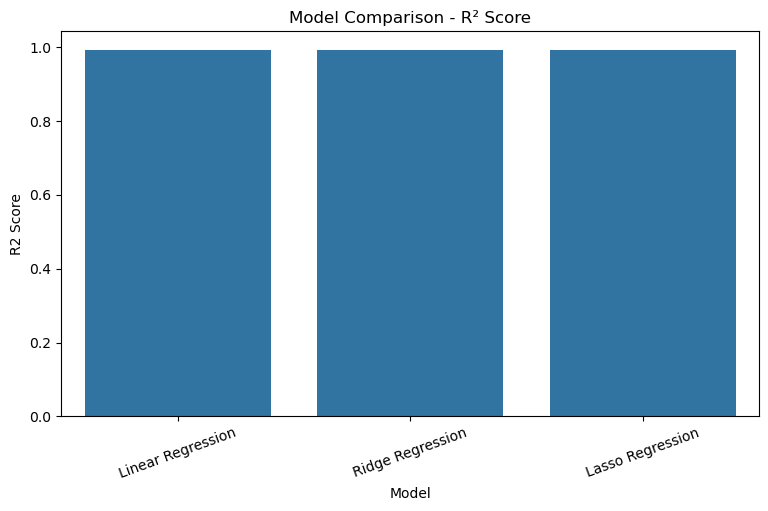

In [ ]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=results,
    x="Model",
    y="R2 Score"
)

plt.title("Model Comparison - R² Score")
plt.xticks(rotation=20)
plt.show()

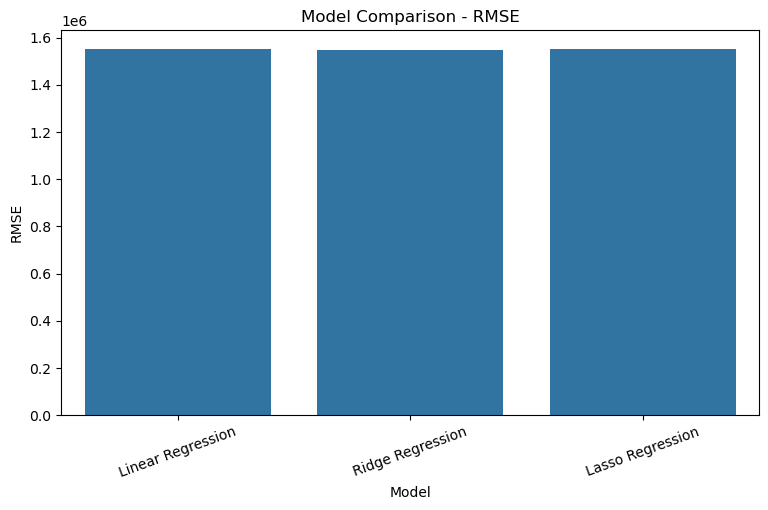

In [61]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=results,
    x="Model",
    y="RMSE"
)

plt.title("Model Comparison - RMSE")
plt.xticks(rotation=20)
plt.show()